In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move_special import *
import pygame

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/Explorables/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [2]:
def create_graph_from_grid_local(grid):
    rows, cols = grid.shape
    G = nx.Graph()

    # Get all active nodes (grid == 1)
    nodes = np.argwhere(grid == 1)
    node_set = set(map(tuple, nodes))
    G.add_nodes_from(node_set)

    # Define the 8-connected neighborhood
    directions = [(-1, -1), (-1, 0), (-1, 1),
                  (0, -1),          (0, 1),
                  (1, -1),  (1, 0), (1, 1)]

    for r, c in node_set:
        for dr, dc in directions:
            nr, nc = (r + dr), (c + dc)
            if nr < rows and nc < cols and nr > 0 and nc > 0:
                if grid[nr, nc] == 1 :
                    neighbor = (nr, nc)
                    if neighbor in node_set:
                        G.add_edge((r, c), neighbor)

    return G

    
def get_largest_connected_component(G):
    try:
        largest_cc = max(nx.connected_components(G), key=len)
        return G.subgraph(largest_cc).copy()
    except ValueError: 
        return nx.Graph() 
    

def component_map_nodes(env, G):
    component_map = {}
    # initialize the component map with default values for the whole lattice of dimensions Lx and Ly
    component_map = {(x, y): [0, 0, 0, 0] for x in range(env.Lx) for y in range(env.Ly)}
    total_nodes = G.number_of_nodes() + env.n_special

    for component in nx.connected_components(G):
        component_nodes = len(component)
        size = component_nodes
        if component_nodes < 2:
            continue

        # compute the number of edges in the component
        # component_edges = sum(1 for u in component for v in G[u] if v in component) // 2
        degree_sum = sum(G.degree(node) for node in component)
 
        # Convert component set to array of coordinates
        coords = np.array(list(component))
        rows = coords[:, 0]
        cols = coords[:, 1]

        # Vectorized rho sum
        sum_rho = np.sum(env.rho[rows, cols])
        avg_rho = sum_rho / env.n

        for node in component:
            degree = G.degree(node)
            #if degree == 0:
            #    component_map[node] = [size, avg_rho, 1, 1]
            #else: 
            component_map[node] = [size, avg_rho, 2*component_nodes/degree_sum, 1/degree]

    return component_map

In [3]:
n = 300
Lx = 32
Ly = 32
delta = 0.3
beta = 4.5
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 1200
beta_special = 4.5
delta_special = 0.3
vision = 9

In [4]:
def reward(state, action, ind, c, env):
    s0 = state[ind, 0]

    mean_s0 = np.mean(s0)
    grid = s0 > k * mean_s0

    G_t = create_graph_from_grid_local(grid)

    central_node = (c, c)
    next_node = (
        central_node[0] + env.directions[action, 0],
        central_node[1] + env.directions[action, 1]
    )
            
    grid_hat = grid.copy()
    grid_hat[next_node[0], next_node[1]] = 1
    G_t_hat = create_graph_from_grid_local(grid_hat)

    degree = G_t_hat.degree(next_node)
    inv_degree = 1 / degree if degree > 0 else 0

    return inv_degree

In [5]:
def reward(state, action, ind, c, env):
    s0 = state[ind, 0]

    mean_s0 = np.mean(s0)
    grid = s0 > k * mean_s0

    G_t = create_graph_from_grid_local(grid)

    central_node = (c, c)
    next_node = (
        central_node[0] + env.directions[action, 0],
        central_node[1] + env.directions[action, 1]
    )
            
    grid_hat = grid.copy()
    grid_hat[next_node[0], next_node[1]] = 1
    G_t_hat = create_graph_from_grid_local(grid_hat)

    degree = G_t_hat.degree(next_node)
    
    rew = 0

    if (not next_node in G_t) and (degree==2):
        rew = 1

    if (not next_node in G_t) and (degree==1):
        rew = 0.75

    if next_node in G_t and (degree==1 or degree==2):
        rew = 0.5

    return rew

In [6]:
def reward(state, new_state, ind, c, alpha = 0.7):
    s0 = state[ind, 0]
    s2 = state[ind, 2]
    ns0 = new_state[ind, 0]
    ns1 = new_state[ind, 1]
    ns2 = new_state[ind, 2]

    mean_s0 = np.mean(s0)
    grid = s0 > k * mean_s0
    G_t_size = np.count_nonzero(grid) + np.sum(s2)

    mean_ns0 = np.mean(ns0)
    grid_t1 = (ns0 > k * mean_ns0) | (ns2 > 0)

    G_t1 = create_graph_from_grid_local(grid_t1)

    g_t1 = 0
    sum_rho = 0
    central_node = (c, c)

    if central_node in G_t1:
        component = nx.node_connected_component(G_t1, central_node)
        g_t1 = len(component)
    else:
        g_t1 = 0


    degree = G_t1.degree(central_node) if central_node in G_t1 else 0
    inv_degree = 1 / degree if degree > 0 else 0

    return g_t1 / G_t_size + alpha*inv_degree 

In [7]:
def reward_max(new_state, ind, c, env):
    ns0 = new_state[ind, 0]
            
    mean_ns0 = np.mean(ns0)
    grid1 = ns0 > k * mean_ns0
    G_t1 = create_graph_from_grid_local(grid1)

    central_node = (c, c)

    max_dist = 0

    for component in nx.connected_components(G_t1):
        if central_node in component:
            lengths = nx.single_source_shortest_path_length(G_t1, central_node)
            max_dist = max(lengths.values()) / (env.vision//2+1)
            break
    
    return max_dist

In [58]:
def reward_op(new_state, ind, c):

    ns_pher = new_state[ind,0]
    ns0 = np.mean(new_state[ind,0])
    plus_id = ns_pher > k*ns0
    minus_id = ns_pher <= k*ns0
    n_plus = np.sum(plus_id)
    n_minus = np.sum(minus_id)

    ns_rho = new_state[ind,1]
    
    #if plus_id[c,c] == 0:
    #    return -1
    
    #else:
    if n_plus == 0 or n_minus == 0:
        return -1
    else:
        mu_plus = np.sum(ns_rho[plus_id])
        mu_minus = np.sum(ns_rho[minus_id])

        if (mu_plus + mu_minus) == 0:
            return -1
        else:            
            return (mu_plus - mu_minus)/(mu_plus + mu_minus)

In [21]:
def reward_op(new_state, ind):

    ns_pher = new_state[ind,0]
    ns0 = np.mean(new_state[ind,0])
    plus_id = ns_pher > ns0
    minus_id = ns_pher <= ns0
    n_plus = np.sum(plus_id)
    n_minus = np.sum(minus_id)

    ns_rho = new_state[ind,1]

    #if plus_id[self.env.vision//2,self.env.vision//2] == 0:
    #    return -1
    
    #else:
    c = vision//2
    grid = plus_id.copy()
    grid[c, c] = 1
    central_node = (c, c)

    G_t1 = create_graph_from_grid_local(grid)
    component = nx.node_connected_component(G_t1, central_node)
    g_t1 = len(component)
    degree = G_t1.degree(central_node)

    component_id = np.zeros((vision, vision), dtype=bool)
    for node in component:
        r, c = node
        component_id[r, c] = True

    if degree == 2 and g_t1 >= vision:
        neighbors = list(G_t1.neighbors(central_node))

        (r1, c1), (r2, c2) = neighbors
        
        condition1 = (abs(r1 - r2) == 2 and abs(c1 - c2) == 2)
        condition2 = (abs(r1 - r2) == 0 and abs(c1 - c2) == 2)
        condition3 = (abs(r1 - r2) == 2 and abs(c1 - c2) == 0)
        aligned = condition1 or condition2 or condition3

        if aligned:
    
            if n_plus == 0 or n_minus == 0:
                return -1
            else:
                mu_plus = np.sum(ns_rho[component_id])
                mu_minus = np.sum(ns_rho) - mu_plus
                local_rho = np.sum(ns_rho)

                if local_rho == 0:
                    return -1
                else:            
                    return (mu_plus - mu_minus)/local_rho
                
        else:
            return -1
    else:
        return -1

In [4]:
def reward_edgepen(new_state):

    ns_pher = new_state[0]
    ns0 = np.mean(new_state[0])
    plus_id = ns_pher > ns0
    minus_id = ns_pher <= ns0
    n_plus = np.sum(plus_id)
    n_minus = np.sum(minus_id)

    c = vision//2
    grid = plus_id.copy()
    grid[c, c] = 1
    central_node = (c, c)

    G_t1 = create_graph_from_grid_local(grid)
    component = nx.node_connected_component(G_t1, central_node)
    n_nodes = len(component)
    # compute the number of edges in the CC
    n_edges = G_t1.subgraph(component).number_of_edges()
    
    if n_nodes == 1:
        edge_pen = 0
    else:
        edge_pen = 1-n_edges/(n_nodes-1)

    #mean_degree = np.mean([d for n, d in G_t1.subgraph(component).degree()])
    
    ns_rho = new_state[1]
    
    pop = 0
    pod = 0
    
    component_id = np.zeros((vision, vision), dtype=bool)
    for node in component:
        r, c = node
        component_id[r, c] = True
    
    if n_plus == 0 or n_minus == 0:
        pod = -1
        pop = 0
    else:
        sigma_plus = np.mean(ns_pher[component_id])
        sigma_minus = np.mean(ns_pher[~component_id])
        sigma_tot = sigma_plus + sigma_minus
        
        mu_plus = np.sum(ns_rho[component_id])
        mu_minus = np.sum(ns_rho) - mu_plus
        local_rho = np.sum(ns_rho)

        if local_rho == 0:
            pod = -1
        else:    
            pod = (mu_plus - mu_minus)/local_rho
            
        if sigma_tot == 0:
            pop = 0
        else:    
            pop = (sigma_plus - sigma_minus)/sigma_tot

    return edge_pen + (pop*min(n_nodes,vision)/vision+pod)/2

In [5]:
env = Ants_move_special(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                            beta_special, delta_special, tmax, n_special, t_transient, vision=vision)
env.transient()

In [6]:
s = env.get_state().copy()
env.update()
new_s = env.get_state().copy()
reward_value = [reward_edgepen(new_s[j]) for j in range(n_special)]
print("Reward:", reward_value)

Reward: [np.float64(-0.6997847814364024), np.float64(-0.1354157684363118), np.float64(-0.6034370706327893), np.float64(-0.32004995817865367), np.float64(-0.6681983216153468), np.float64(-0.6099241128402418), np.float64(-0.9176418751604525), np.float64(-0.4400698966491701), np.float64(-0.7522278213265663), np.float64(-0.34209331976093127), np.float64(-0.4627548276079842), np.float64(-0.8208677748401956), np.float64(-0.7610297858891018), np.float64(-0.9915502520263901), np.float64(-0.6409022894198381), np.float64(-0.7228731027054883), np.float64(-0.6512523203175018), np.float64(-0.4656435672326321), np.float64(-0.9888746740282286), np.float64(-0.8532254879961026), np.float64(-0.35592497836593157), np.float64(-0.6039782398692909), np.float64(-0.3855344894862975), np.float64(-0.6370505951508267), np.float64(-0.45939776643815344), np.float64(-0.5355669955958579), np.float64(-0.6266365043275599), np.float64(-0.4594725268649254), np.float64(-0.5178745944834509), np.float64(-0.5464176381789103

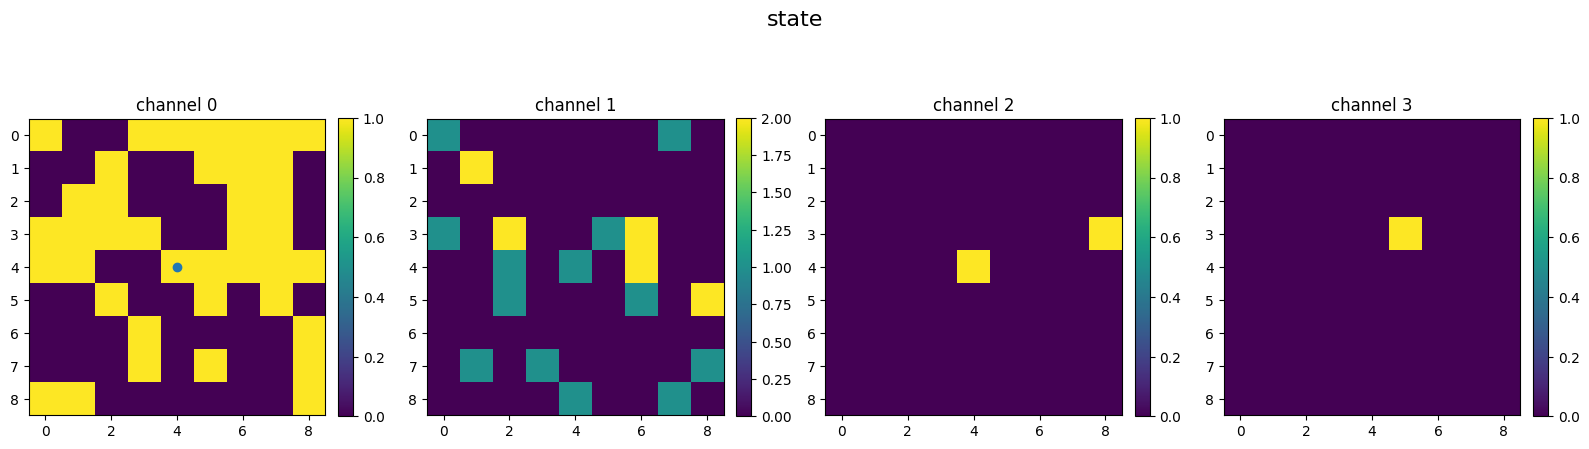

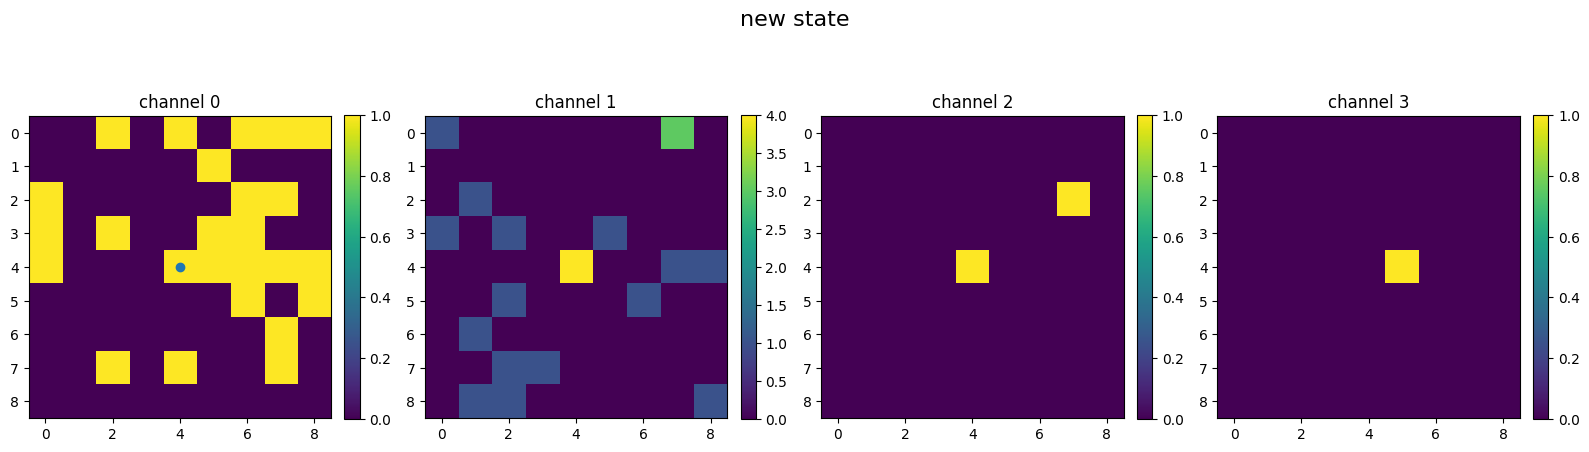

In [7]:
j = 0

# Plot dello stato: 4 immagini affiancate
fig, axs = plt.subplots(1, 4, figsize=(16, 5))
for i in range(4):
    if i == 0:
        im = axs[i].imshow(s[j, i]>(np.mean(s[j, i])), cmap='viridis')
        axs[i].scatter(4,4)
    else:
        im = axs[i].imshow(s[j, i], cmap='viridis')
    axs[i].set_title(f"channel {i}")
    fig.colorbar(im, ax=axs[i], fraction=0.046, pad=0.04)

plt.suptitle("state", fontsize=16)
plt.tight_layout()
plt.show()

# Plot dello stato: 4 immagini affiancate
fig, axs = plt.subplots(1, 4, figsize=(16, 5))
for i in range(4):
    if i == 0:
        im = axs[i].imshow(new_s[j, i]>(np.mean(new_s[j, i])), cmap='viridis')
        axs[i].scatter(4,4)
    else:
        im = axs[i].imshow(new_s[j, i], cmap='viridis')
    axs[i].set_title(f"channel {i}")
    fig.colorbar(im, ax=axs[i], fraction=0.046, pad=0.04)

plt.suptitle("new state", fontsize=16)
plt.tight_layout()
plt.show()

In [8]:
def compute_avg_res(env):

    # rew_n_list = []
    rew_list = []

    # res = np.zeros(8)

    for t in range(tmax-t_transient):
        
        s = env.get_state().copy()
        env.update()
        new_s = env.get_state().copy()

        rews = [reward_edgepen(new_s[j]) for j in range(n_special)]
        # rews_n = [reward_n(component_map,  env, site[0], site[1], alpha)[3] for site in env.positions[env.n:]]
        #rews = [item if item is not None else [0, 0, 0] for item in rews]
        # rew_n_list.append(rews_n)
        rew_list.append(rews)

    rew_list = np.array(rew_list)
    #rew_n_list = np.array(rew_n_list)

    # res = np.concatenate((rew_list,rew_n_list), axis=2)
    avg_res = np.mean(rew_list)#, axis=(0,1))

    return avg_res

In [12]:
#phi_list = np.linspace(0.0, 0.9,1)# 5)
beta_list = np.linspace(3.5, 9.5, 7)
delta_list = np.linspace(0.3, 0.8, 6)# 5)

res_matrix = np.zeros((len(beta_list), len(delta_list), 1))
pos_list = np.zeros((len(beta_list), len(delta_list), n+n_special, 2))
pher_list = np.zeros((len(beta_list), len(delta_list), Lx, Ly)) 

for i, beta_s in enumerate(beta_list):
    for j, delta_s in enumerate(delta_list):

        env = Ants_move_special(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                            beta_s, delta_s, tmax, n_special, t_transient, vision=vision)
    
        env.reset_objects()
        env.transient()

        print(beta_list[i], delta_list[j])
        res_matrix[i,j,:] = compute_avg_res(env)
        pos_list[i, j] = env.positions.copy()
        pher_list[i, j] = env.pheromones.copy()   

3.5 0.3
3.5 0.4
3.5 0.5
3.5 0.6000000000000001
3.5 0.7
3.5 0.8
4.5 0.3
4.5 0.4
4.5 0.5
4.5 0.6000000000000001
4.5 0.7
4.5 0.8
5.5 0.3
5.5 0.4
5.5 0.5
5.5 0.6000000000000001
5.5 0.7
5.5 0.8
6.5 0.3
6.5 0.4
6.5 0.5
6.5 0.6000000000000001
6.5 0.7
6.5 0.8
7.5 0.3
7.5 0.4
7.5 0.5
7.5 0.6000000000000001
7.5 0.7
7.5 0.8
8.5 0.3
8.5 0.4
8.5 0.5
8.5 0.6000000000000001
8.5 0.7
8.5 0.8
9.5 0.3
9.5 0.4
9.5 0.5
9.5 0.6000000000000001
9.5 0.7
9.5 0.8


In [13]:
def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0 = (n*eta + n_special*eta_special)/(decay_rate*Lx**2)

print(decay_rate*Lx**2/(eta_special*n_special)+eta*n/(eta_special*n_special)*beta/(s0 + s0**2 + 2*delta*s0 + delta*s0**2 + delta**2*s0**2))

0.557669332796494


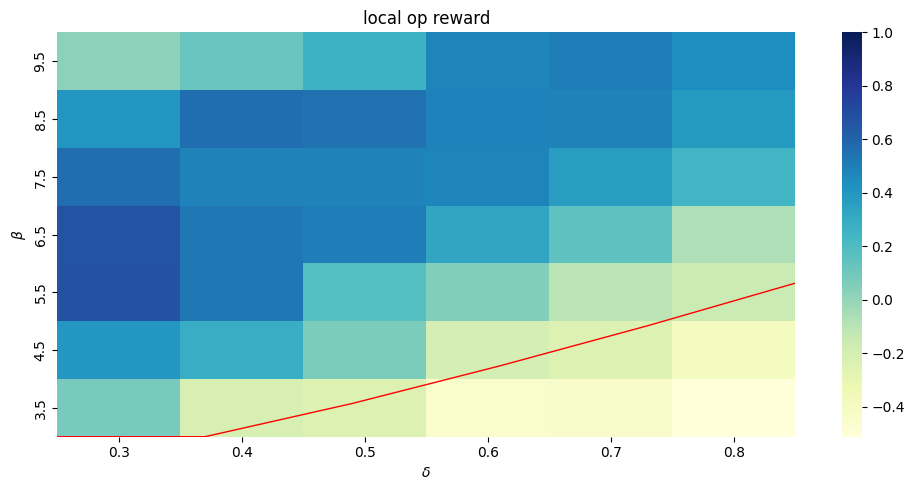

In [19]:
fig, axes = plt.subplots(1, 1, figsize=(10, 5))  # 2 rows x 4 columns
#axes = axes.flatten()  # Flatten to make indexing easier

ax = axes
sns.heatmap(res_matrix[:,:,0],
            xticklabels=[f"{delta:.1f}" for delta in delta_list],
            yticklabels=[f"{beta:.1f}" for beta in beta_list],
            cmap='YlGnBu',
            vmin=np.min(res_matrix[:,:,0]), vmax=1,   # Set fixed color scale
            ax=ax)

beta_critic = beta_crit(delta_list, s0)

x_positions = np.linspace(0, len(delta_list), len(delta_list))
y_positions = np.interp(beta_critic, beta_list, np.arange(len(beta_list)))  # Map beta_critic to heatmap indices

ax.plot(x_positions, y_positions, color='red', linewidth=1, label=r'$\beta_c$')

ax.invert_yaxis()
ax.set_xlabel(r"$\delta$")
ax.set_ylabel(r"$\beta$")
ax.set_title(f'local op reward')

plt.tight_layout()
plt.show()

/tmp/ipykernel_24385/3946645706.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


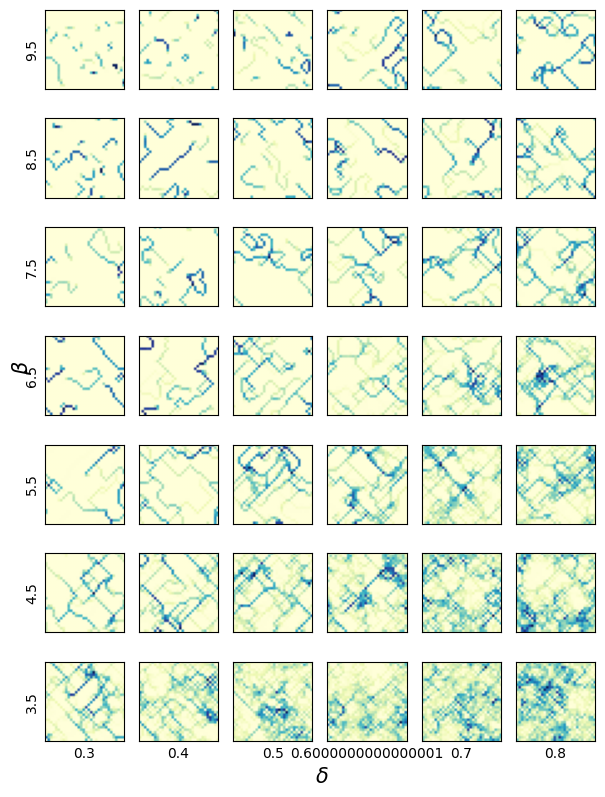

In [15]:
fig, ax = plt.subplots(len(beta_list), len(delta_list), figsize=(6,8))

for i,beta in enumerate(beta_list):
    for j,delta in enumerate(delta_list):

        ax[i,j].imshow(pher_list[len(beta_list)-i-1,j].T[::-1], cmap='YlGnBu')
        ax[i,j].set_xticks([])
        ax[i,j].set_yticks([])

        if j == 0:
            ax[i,j].set_ylabel(f'{beta_list[len(beta_list)-i-1]}', fontsize=10)

        if i == len(beta_list) - 1:
            ax[i,j].set_xlabel(f'{delta}', fontsize=10)

# Now, overlay a new axes for the curve plot
# Add an inset or new axes covering the whole grid area
ax_curve = fig.add_axes([0.1, 0.1, 0.8, 0.8], frameon=False)
ax_curve.plot(delta_list, [beta_crit(s0, delta) for delta in delta_list], color='red', linestyle='--', linewidth=2)
ax_curve.set_xlim(0,0.5)
ax_curve.set_ylim(0.5, 7.5)
ax_curve.set_xticks([])
ax_curve.set_yticks([])


fig.text(0.0, 0.52, r'$\beta$', fontsize=15, va='center', rotation='vertical')
fig.text(0.52, 0.0, r'$\delta$', fontsize=15, ha='center')

plt.tight_layout()
plt.show()

TypeError: 'numpy.ndarray' object is not callable

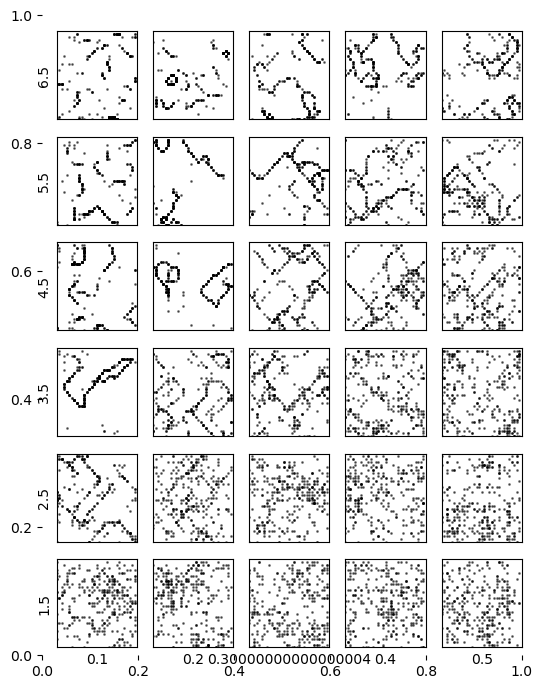

In [13]:
fig, ax = plt.subplots(len(beta_list), len(delta_list), figsize=(6,8))

for i,beta in enumerate(beta_list):
    for j,delta in enumerate(delta_list):

        ax[i,j].scatter(pos_list[len(beta_list)-i-1,j,:,0],pos_list[len(beta_list)-i-1,j,:,1], s=1, c='black', alpha=0.5)
        ax[i,j].set_xlim(0,Lx)
        ax[i,j].set_ylim(0,Ly)
        ax[i,j].set_xticks([])
        ax[i,j].set_yticks([])

        if j == 0:
            ax[i,j].set_ylabel(f'{beta_list[len(beta_list)-i-1]}', fontsize=10)

        if i == len(beta_list) - 1:
            ax[i,j].set_xlabel(f'{delta}', fontsize=10)

# Now, overlay a new axes for the curve plot
# Add an inset or new axes covering the whole grid area
ax_curve = fig.add_axes([0.1, 0.1, 0.8, 0.8], frameon=False)
ax_curve.plot(delta_list, [beta_critic(s0, delta) for delta in delta_list], color='red', linestyle='--', linewidth=2)
ax_curve.set_xlim(0,0.5)
ax_curve.set_ylim(0.5, 7.5)
ax_curve.set_xticks([])
ax_curve.set_yticks([])

fig.text(0.0, 0.52, r'$\beta$', fontsize=15, va='center', rotation='vertical')
fig.text(0.52, 0.0, r'$\delta$', fontsize=15, ha='center')

plt.tight_layout()
plt.show()



In [14]:
rew_list = []

k = 2
delta_special = 0.3
beta_special = 4.5

env = Ants_move_special(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                            beta_special, delta_special, tmax, n_special, t_transient, vision=vision)

env.reset_objects()
env.transient()

# res = np.zeros(8)

for t in range(tmax-t_transient):
    
    s = env.get_state().copy()
    env.update()
    new_s = env.get_state().copy()

    rews = [reward_op(s,j) for j in range(n_special)]   
    rew_list.append(rews)

rew_list = np.array(rew_list)

In [15]:
rew_list.shape

(1000, 30)

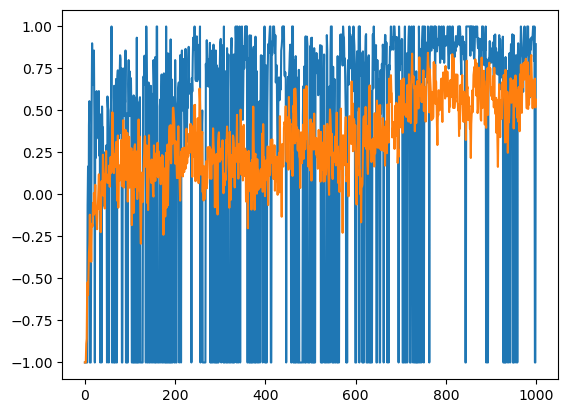

In [16]:
plt.plot(rew_list[:,0])
plt.plot(np.mean(rew_list, axis=1))


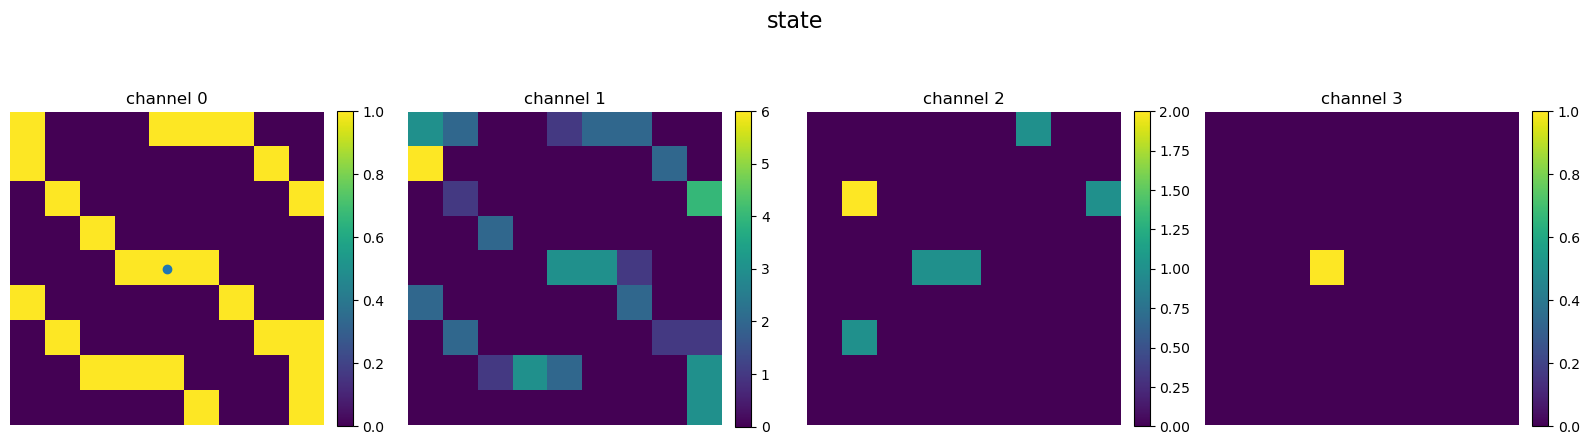

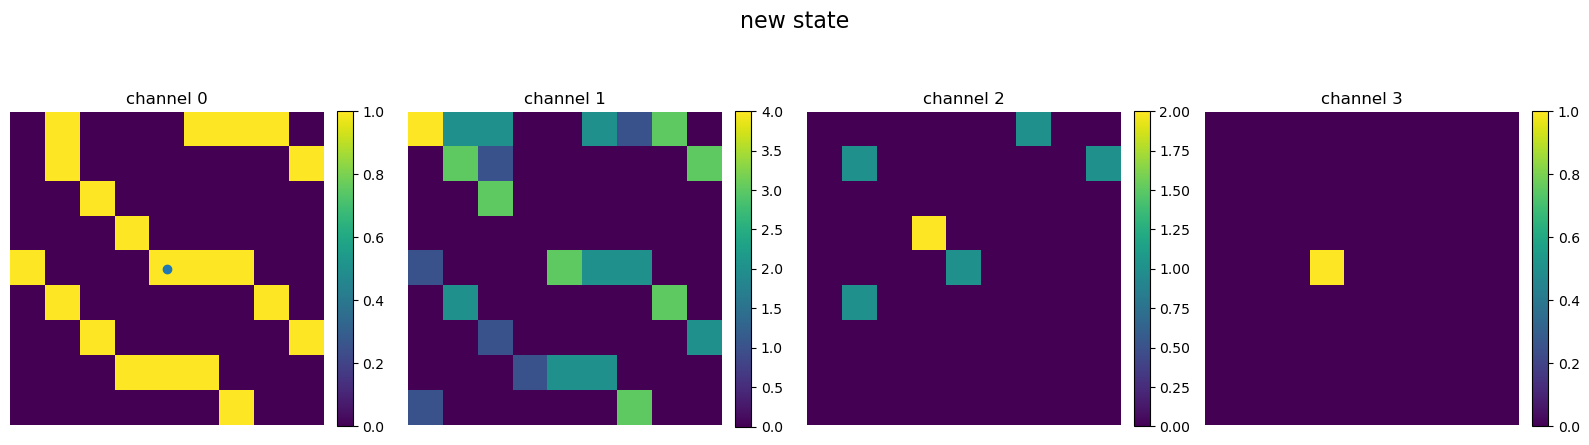

0.8846153846153846


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

j = np.random.randint(0,n_special)

# Plot dello stato: 4 immagini affiancate
fig, axs = plt.subplots(1, 4, figsize=(16, 5))
for i in range(4):
    if i == 0:
        im = axs[i].imshow(s[j, i]>(2*np.mean(s[j, i])), cmap='viridis')
        axs[i].scatter(4,4)
    else:
        im = axs[i].imshow(s[j, i], cmap='viridis')
    axs[i].set_title(f"channel {i}")
    axs[i].axis('off')
    fig.colorbar(im, ax=axs[i], fraction=0.046, pad=0.04)

plt.suptitle("state", fontsize=16)
plt.tight_layout()
plt.show()

# Plot dello stato: 4 immagini affiancate
fig, axs = plt.subplots(1, 4, figsize=(16, 5))
for i in range(4):
    if i == 0:
        im = axs[i].imshow(new_s[j, i]>(2*np.mean(s[j, i])), cmap='viridis')
        axs[i].scatter(4,4)
    else:
        im = axs[i].imshow(new_s[j, i], cmap='viridis')
    axs[i].set_title(f"channel {i}")
    axs[i].axis('off')
    fig.colorbar(im, ax=axs[i], fraction=0.046, pad=0.04)

plt.suptitle("new state", fontsize=16)
plt.tight_layout()
plt.show()


print(rew_list[-1,j])

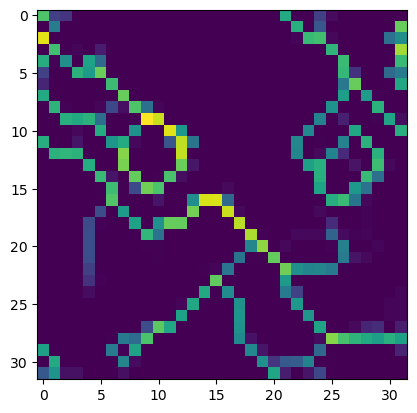

In [18]:
plt.imshow(env.pheromones)